<a href="https://colab.research.google.com/github/huzaifamachinelearning/Virexo-internship/blob/main/virexo_first_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Summary of each step
#Creating the dataset
columns are generated using uniform distribution and normal distribution. Scores calculated by summing weighted columns are used to generate the target.Lastly in some rows, null values are introduced and a roll_no column is added

#Exploring the data
target column is fairly balanced. Average of columns for pass and fail classes have minor gap(the largest being of attendance_percentage) suggesting weak signals. We bin study hour column into two classes based on pass rates for study hours

# preprocessing pipeline
Two pipeline versions are created. One just imputes and scales all the columns. The other additionally creates a binned study hour column and turns it into one hot vectors. As none of the columns are long tailed no log transform etc are performed.

# Training and evaluating models
The base score that we have to beat is 55%.Accuracy is a reliable metric due to balance of the targe class

For SVC the simpler pipeline (without binned hour) wins out so we use the simple  pipeline for subsequent models.

svc has accuracy of  98.6%. logistic regression has 98.8% accuracy and overtakes the svc on almost all metrics with a slight margin.Random forest has 93% accuracy

svc does not overfit logistic regression has slight overfitting and random forest overfits badlly compared to other

#Fine Tuning and prediction

we fine tune logistic regression and get an l1 penalty model. The accuracy on the test set is 98.5% vs 99.2% on the validation set signaling a slight overfit over the validation set probably because of our fine tuning.

By inspecting the models we see that the most important feature is attendance_percentage which confirms our intuition in data exploration phase

---------------------------------------

# Creating the dataset
columns are generated using uniform distribution and normal distribution. Scores calculated by summing weighted columns are used to generate the target.Lastly in some rows, null values are introduced and a roll_no column is added

##Creating Columns

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
n_features=4
n_instances=1000

# random_generator
rand_generator=np.random.default_rng(seed=42)

#study_hour_per_day
study_hour_per_day=rand_generator.integers(0,11,size=n_instances)

#attendance_percentage
attendance_percentage=np.round(np.clip(
    rand_generator.normal(loc=60, scale=12, size=n_instances),
    0,
    100
),2)

#previous_marks
previous_marks = np.round(np.clip(
    rand_generator.normal(loc=60, scale=15, size=n_instances),
    0,
    100
),2)

#assignment_percentage
assignment_percentage = np.round(np.clip(
    rand_generator.normal(loc=70, scale=8, size=n_instances),
    0,
    100
),2)

# combining all cols
X=np.c_[study_hour_per_day,attendance_percentage,previous_marks,assignment_percentage]
X.shape


(1000, 4)

##Distribution of columns

array([[<Axes: title={'center': 'study_hour_per_day'}>,
        <Axes: title={'center': 'attendance_percentage'}>],
       [<Axes: title={'center': 'previous_marks'}>,
        <Axes: title={'center': 'assignment_percentage'}>]], dtype=object)

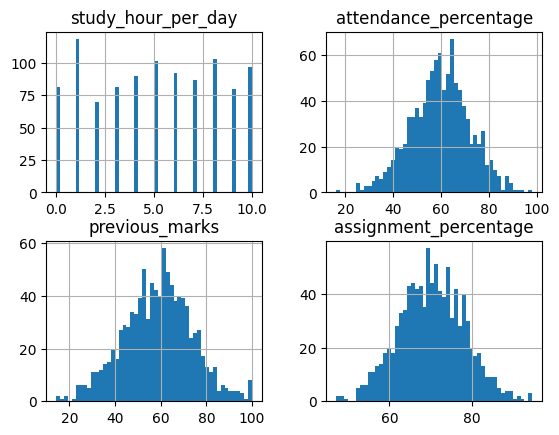

In [ ]:
columns=['study_hour_per_day','attendance_percentage','previous_marks','assignment_percentage']
X_df=pd.DataFrame(X,columns=columns)
X_df.hist(bins=50)


##Using scores to generate the target

In [ ]:
noise=1
scores=(0.10*study_hour_per_day+
0.30*attendance_percentage+
0.10*previous_marks+
0.40*assignment_percentage)

# subtracting scores.mean() to set the decision thresold to zero
#  and adding noise
scores=scores-scores.mean()+rand_generator.normal(0,noise)
y=(scores>0).astype(int)


##Adding null rows
using random generator to determine the rows to have null values

In [ ]:
null_cols=[1,2]
null_rows=10
print(null_rows)

#using random generator to determine the rows to have null values
null_row_indices=rand_generator.permutation(n_instances)[:null_rows]

# setting to nan
X[np.ix_(null_row_indices,null_cols)]=np.nan
np.sum(np.isnan(X))

10


np.int64(20)

In [ ]:
columns=['study_hour_per_day','attendance_percentage','previous_marks','assignment_percentage','result']
data=pd.DataFrame(np.c_[X,y],columns=columns)
data

,study_hour_per_day,attendance_percentage,previous_marks,assignment_percentage,result
0,0.0,77.20,68.45,62.95,1.0
1,8.0,61.10,61.72,71.74,1.0
2,7.0,66.97,64.95,69.71,1.0
3,4.0,59.32,71.66,69.20,1.0
4,4.0,57.96,47.86,69.09,0.0
...,...,...,...,...,...
995,6.0,85.15,29.53,52.90,0.0
996,5.0,42.51,63.18,68.22,0.0
997,3.0,55.31,71.43,79.10,1.0
998,10.0,80.47,55.80,70.15,1.0


## generating roll_no col

In [ ]:
data=data.reset_index()
data['index']=data['index']+1 # roll_no start from 1
data=data.rename(columns={'index':'roll_no'})
data

,roll_no,study_hour_per_day,attendance_percentage,previous_marks,assignment_percentage,result
0,1,0.0,77.20,68.45,62.95,1.0
1,2,8.0,61.10,61.72,71.74,1.0
2,3,7.0,66.97,64.95,69.71,1.0
3,4,4.0,59.32,71.66,69.20,1.0
4,5,4.0,57.96,47.86,69.09,0.0
...,...,...,...,...,...,...
995,996,6.0,85.15,29.53,52.90,0.0
996,997,5.0,42.51,63.18,68.22,0.0
997,998,3.0,55.31,71.43,79.10,1.0
998,999,10.0,80.47,55.80,70.15,1.0


## saving the data

In [ ]:
data.to_csv('virexo_first_task_data.csv',index=False)

# Exploring the data
target column is fairly balanced. Average of columns for pass and fail classes have minor gap(the largest being of attendance_percentage) suggesting weak signals. We bin study hour column into two classes based on pass rates for study hours


## loading the data

In [ ]:
def load_data(path):
  return pd.read_csv(path)
std_perf_data=load_data('virexo_first_task_data.csv')
std_perf_data


,roll_no,study_hour_per_day,attendance_percentage,previous_marks,assignment_percentage,result
0,1,0.0,77.20,68.45,62.95,1.0
1,2,8.0,61.10,61.72,71.74,1.0
2,3,7.0,66.97,64.95,69.71,1.0
3,4,4.0,59.32,71.66,69.20,1.0
4,5,4.0,57.96,47.86,69.09,0.0
...,...,...,...,...,...,...
995,996,6.0,85.15,29.53,52.90,0.0
996,997,5.0,42.51,63.18,68.22,0.0
997,998,3.0,55.31,71.43,79.10,1.0
998,999,10.0,80.47,55.80,70.15,1.0


## basic info about the dataset

note that target is fairly balanced between the two classes

In [ ]:
std_perf_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   roll_no                1000 non-null   int64  
 1   study_hour_per_day     1000 non-null   float64
 2   attendance_percentage  990 non-null    float64
 3   previous_marks         990 non-null    float64
 4   assignment_percentage  1000 non-null   float64
 5   result                 1000 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 47.0 KB


In [ ]:
std_perf_data.describe()

,roll_no,study_hour_per_day,attendance_percentage,previous_marks,assignment_percentage,result
count,1000.000000,1000.000000,990.000000,990.000000,1000.000000,1000.000000
mean,500.500000,5.041000,59.819737,58.683061,70.314900,0.574000
std,288.819436,3.168179,12.258966,15.131123,7.942203,0.494741
min,1.000000,0.000000,16.220000,14.040000,47.110000,0.000000
25%,250.750000,2.000000,51.892500,48.770000,64.812500,0.000000
50%,500.500000,5.000000,60.120000,59.505000,70.180000,1.000000
75%,750.250000,8.000000,67.672500,68.745000,75.922500,1.000000
max,1000.000000,10.000000,98.150000,100.000000,94.710000,1.000000


In [ ]:
# target is fairly balanced
std_perf_data['result'].value_counts(normalize=True)

,proportion
result,
1.0,0.574
0.0,0.426


<Figure size 5000x5000 with 0 Axes>

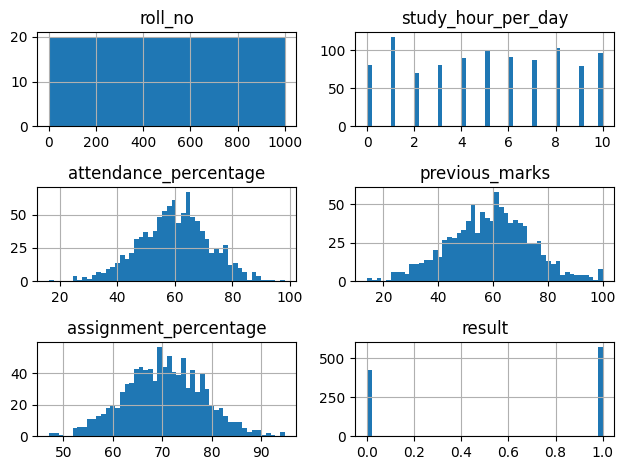

In [ ]:
plt.figure(figsize=(50,50))
std_perf_data.hist(bins=50)
plt.tight_layout()
plt.show()


## Splitting the data into train and test set


In [ ]:

from sklearn.model_selection import train_test_split
df_train,df_test=train_test_split(std_perf_data,test_size=0.2,random_state=42)


In [ ]:
df_explore=df_train.copy()

## Calculating average value of a column for each of the target class
as expected study_hour_per_day,attnedance_percentage,previous_marks and assignment percentage have lower average for failing students with attendance_percentage having the most gap betweeen passing and failing students of 20%. However overall, the gap is fairly minimal suggesting weak signals

In [ ]:
def relative_decrease(x,y):
  return np.abs(x-y)/max(x,y)
relative_decrease(2,5)


np.float64(0.6)

### std_per_hour_means

0.08734941979169983


<Axes: xlabel='result'>

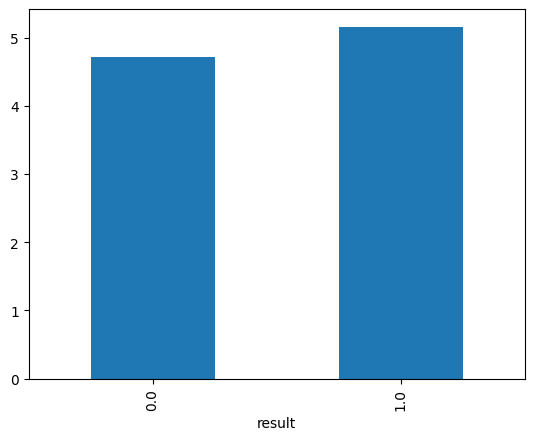

In [ ]:
std_per_hour_means=df_explore.groupby('result')['study_hour_per_day'].mean()
print(relative_decrease(std_per_hour_means[1],std_per_hour_means[0]))
std_per_hour_means.plot(kind='bar')


### attendance_means

0.20482441572213553


<Axes: xlabel='result'>

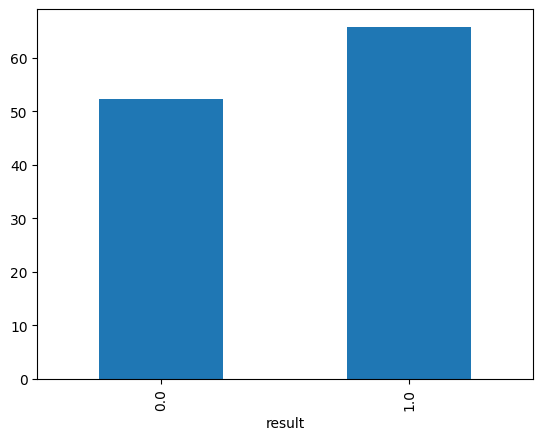

In [ ]:
attendance_means=df_explore.groupby('result')['attendance_percentage'].mean()
print(relative_decrease(attendance_means[0],attendance_means[1]))
attendance_means.plot(kind='bar')

### prev_marks_means

0.10540496917747727


<Axes: xlabel='result'>

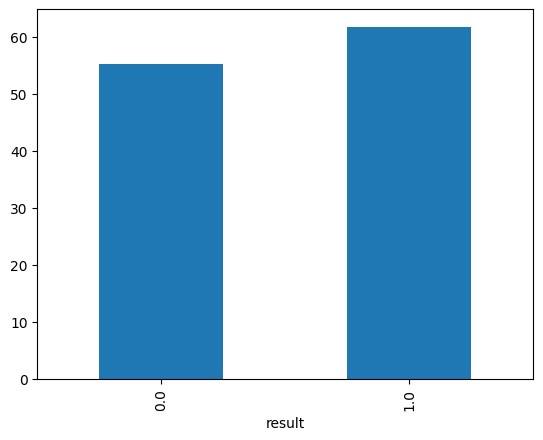

In [ ]:
prev_marks_means=df_explore.groupby('result')['previous_marks'].mean()
print(relative_decrease(prev_marks_means[0],prev_marks_means[1]))
prev_marks_means.plot(kind='bar')


### assignment_percentage_means

0.10782432354871095


<Axes: xlabel='result'>

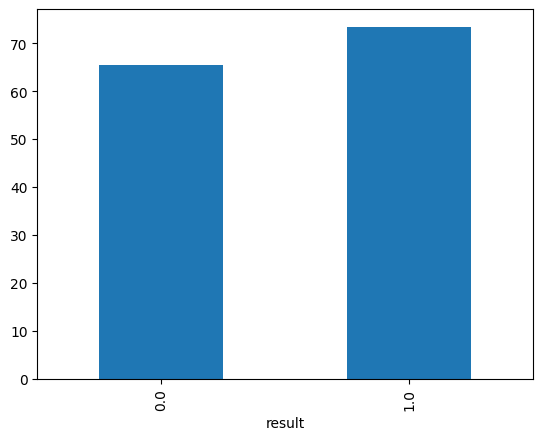

In [ ]:
assign_means=df_explore.groupby('result')['assignment_percentage'].mean()
print(relative_decrease(assign_means[0],assign_means[1]))
assign_means.plot(kind='bar')


## mean pass rate for study hours

study hours 0,7,8,9,10 seem to have similar pass rates,and study hours 1,2,3,4,5,6 seem to have similar pass rates. We bin the study hour column into two classes considering it as a preprocessing option

<Axes: xlabel='study_hour_per_day'>

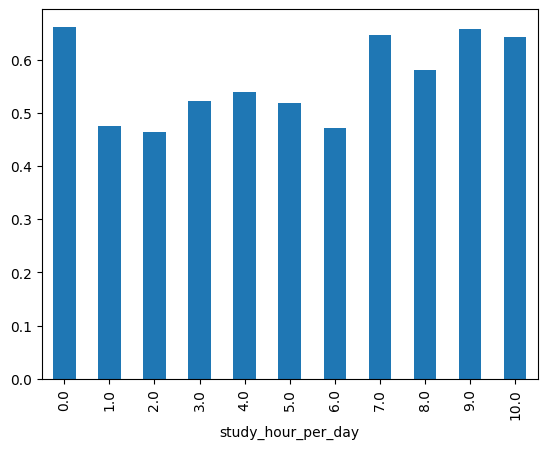

In [ ]:
df_explore.groupby('study_hour_per_day')['result'].mean().plot(kind='bar')

In [ ]:
df_explore["study_hours_bin"] = np.where(
    (df_explore["study_hour_per_day"] == 0) | (df_explore["study_hour_per_day"] >= 7),
    "first",
    "second"
)

In [ ]:
df_explore.groupby('study_hours_bin')['result'].mean()

,result
study_hours_bin,
first,0.635328
second,0.498886


# preprocessing pipeline
Two pipeline versions are created. One just imputes and scales all the columns. The other additionally creates a binned study hour column and turns it into one hot vectors. As none of the columns are long tailed no log transform etc are performed.

In [ ]:
X_train,y_train=df_train.drop('result',axis=1),df_train['result'].copy()

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import OneHotEncoder
# simple version of pipeline including imputing and scaling
preprocessing_pipeline=make_pipeline(SimpleImputer(strategy='median'),StandardScaler())

# columns for pipeline version 2
columns_for_v_2=['attendance_percentage','previous_marks','assignment_percentage','study_hour_per_day']

# function that returns processing pipeline for the binned studyhours
def new_hours_pipeline():
  return make_pipeline(
      SimpleImputer(strategy='most_frequent'),
      FunctionTransformer(lambda X:np.where(((X[:,0]==0) | (X[:,0]>=7)),'first','second').reshape(-1,1)),
      OneHotEncoder(handle_unknown='ignore',sparse_output=False)
  )

# pipeline version 2
preprocessing_pipeline_v_2=ColumnTransformer(
    [
        ('simple_preprocessing',preprocessing_pipeline,columns_for_v_2),
        ('new_hours',new_hours_pipeline(),['study_hour_per_day']) # for binned study hours
    ]
)




# Training and evaluating models
The base score that we have to beat is 55%.Accuracy is a reliable metric due to balance of the targe class

For SVC the simpler pipeline (without binned hour) wins out so we use the simple  pipeline for subsequent models.

svc has accuracy of  98.6%. logistic regression has 98.8% accuracy and overtakes the svc on almost all metrics with a slight margin.Random forest has 93% accuracy

svc does not overfit logistic regression has slight overfitting and random forest overfits badlly compared to other

## Base score
dummy classifier gives us base score that a model has to beat (55%). As target column is fairly balanced. Accuracy is a fair metric

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
dum_clf=DummyClassifier()
dum_clf.fit(X_train.iloc[:,1:],y_train)
pred=dum_clf.predict(X_train)
accuracy_score(y_train,pred)


0.55875

In [ ]:
y_train.value_counts(normalize=True)

,proportion
result,
1.0,0.55875
0.0,0.44125


## Helper functions

In [ ]:
from sklearn.model_selection import cross_val_predict

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# if train=False gets clean scores for each of the instances
# and calcualte metrics. Otherwise trains the model and get scores on
# on the same dataset. Useful for determining over fitting
def evaluate(name, model, X, y, method='predict_proba', threshold=0.5,train=False, cv=3):



    if train:
      model.fit(X,y)
      raw = model.predict_proba(X) if method == 'predict_proba' else model.decision_function(X)
    else:
      raw = cross_val_predict(model, X, y, cv=cv, method=method)
    scores = raw[:, 1] if method == 'predict_proba' else raw
    pred = scores >= threshold
    acc = accuracy_score(y, pred)
    prec_score=precision_score(y, pred, zero_division=0)
    rec_score=recall_score(y, pred)
    f1=f1_score(y, pred)
    ap, auc = average_precision_score(y, scores), roc_auc_score(y, scores)

    return {'name': name,
            'accuracy': acc,
            'ap': ap,
            'roc_auc': auc,
            'precision_score':prec_score,
            'recall_score':rec_score,
            'f1_score':f1,
            'confusion_matrix':confusion_matrix(y, pred)
            }

In [ ]:
def classification_report(y,pred):
  return {
       'acc':accuracy_score(y,pred),
      'prec':precision_score(y,pred),
      'recall_score':recall_score(y,pred),
       'f1_score':f1_score(y,pred),
       'confusion_matrix':confusion_matrix(y,pred)

  }

# SVM

We test out both versions of our preprocessing pipeline. It turns out our study hour binning technique did not workout the version without it work better on all metrics. For the better performing pipeline accuracy score is about 98.6% with little to no overfitting

## trying with simple preprocessing


In [ ]:
from sklearn.svm import SVC
svc_model=SVC(kernel='linear')
full_pipeline=Pipeline(
    [
        ('preprocessing',preprocessing_pipeline),
        ('svc_model',svc_model)
    ]
)
evaluate(
    'svc-first-pipeline',
    full_pipeline,
    X_train.iloc[:,1:],y_train, # to exclude roll_no col
    method='decision_function',
    threshold=0, # default thersold for svc is 0
    train=True,
    cv=4

    )

{'name': 'svc-first-pipeline',
 'accuracy': 0.985,
 'ap': np.float64(0.9978759597606518),
 'roc_auc': np.float64(0.9974903511607126),
 'precision_score': 0.9909706546275395,
 'recall_score': 0.9821029082774049,
 'f1_score': 0.9865168539325843,
 'confusion_matrix': array([[349,   4],
        [  8, 439]])}

In [ ]:
v_1_validation=evaluate(
    'svc-first-pipeline',
    full_pipeline,
    X_train.iloc[:,1:],y_train,# to exclude roll_no col
    method='decision_function',
    threshold=0,
    cv=4

    )
v_1_validation

{'name': 'svc-first-pipeline',
 'accuracy': 0.98625,
 'ap': np.float64(0.9977736085566938),
 'roc_auc': np.float64(0.9973699387164032),
 'precision_score': 0.990990990990991,
 'recall_score': 0.9843400447427293,
 'f1_score': 0.9876543209876543,
 'confusion_matrix': array([[349,   4],
        [  7, 440]])}

## trying with version 2 preprocessing

In [ ]:
from sklearn.svm import SVC
svc_model=SVC(kernel='linear')
full_pipeline=Pipeline(
    [
        ('preprocessing',preprocessing_pipeline_v_2),
        ('svc_model',svc_model)
    ]
)
evaluate(
    'svc-first-pipeline',
    full_pipeline,
    X_train.iloc[:,1:],y_train,
    method='decision_function',
    threshold=0,
    train=True,
    cv=4

    )


{'name': 'svc-first-pipeline',
 'accuracy': 0.98375,
 'ap': np.float64(0.9978971875321185),
 'roc_auc': np.float64(0.9974776761665748),
 'precision_score': 0.9909502262443439,
 'recall_score': 0.9798657718120806,
 'f1_score': 0.9853768278965129,
 'confusion_matrix': array([[349,   4],
        [  9, 438]])}

In [ ]:
v_2_validation=evaluate(
    'svc-first-pipeline',
    full_pipeline,
    X_train,y_train,
    method='decision_function',
    threshold=0,
    cv=4

    )
v_1_validation,v_2_validation

({'name': 'svc-first-pipeline',
  'accuracy': 0.98625,
  'ap': np.float64(0.9977736085566938),
  'roc_auc': np.float64(0.9973699387164032),
  'precision_score': 0.990990990990991,
  'recall_score': 0.9843400447427293,
  'f1_score': 0.9876543209876543,
  'confusion_matrix': array([[349,   4],
         [  7, 440]])},
 {'name': 'svc-first-pipeline',
  'accuracy': 0.9825,
  'ap': np.float64(0.9978090997317197),
  'roc_auc': np.float64(0.9973699387164033),
  'precision_score': 0.9887133182844243,
  'recall_score': 0.9798657718120806,
  'f1_score': 0.9842696629213483,
  'confusion_matrix': array([[348,   5],
         [  9, 438]])})

# Logistic Regression
This is the best model. It beats svc (though by a minor margin) on accuracy,f1_score and recall_score,although it slightly overfits

  'accuracy': 98.8%, 98.6%
  'precision_score':99.1%,99.1%
  'recall_score': 98.7%,98.4%
  'f1_score': 98.9%,98.8%


In [ ]:
from sklearn.linear_model import LogisticRegression
logistic_reg_model=LogisticRegression()
full_pipeline=Pipeline(
    [
        ('preprocessing',preprocessing_pipeline),
        ('logistic_model',logistic_reg_model)
    ]
)
evaluate(
    'logistic-pipeline',
    full_pipeline,
    X_train.iloc[:,1:],y_train,
    method='predict_proba',
    threshold=0.5,
    train=True,


    )

{'name': 'logistic-pipeline',
 'accuracy': 0.99,
 'ap': np.float64(0.9979292414990238),
 'roc_auc': np.float64(0.9975537261314016),
 'precision_score': 0.9910514541387024,
 'recall_score': 0.9910514541387024,
 'f1_score': 0.9910514541387024,
 'confusion_matrix': array([[349,   4],
        [  4, 443]])}

In [ ]:
logistic_validation=evaluate(
    'logistic_pipeline',
    full_pipeline,
    X_train.iloc[:,1:],y_train,
    method='predict_proba',
    cv=4

    )
logistic_validation,v_1_validation

({'name': 'logistic_pipeline',
  'accuracy': 0.9875,
  'ap': np.float64(0.9977430654802838),
  'roc_auc': np.float64(0.9973509262251966),
  'precision_score': 0.9910112359550561,
  'recall_score': 0.9865771812080537,
  'f1_score': 0.9887892376681614,
  'confusion_matrix': array([[349,   4],
         [  6, 441]])},
 {'name': 'svc-first-pipeline',
  'accuracy': 0.98625,
  'ap': np.float64(0.9977736085566938),
  'roc_auc': np.float64(0.9973699387164032),
  'precision_score': 0.990990990990991,
  'recall_score': 0.9843400447427293,
  'f1_score': 0.9876543209876543,
  'confusion_matrix': array([[349,   4],
         [  7, 440]])})

## printing rounded values

In [ ]:
for value in list(logistic_validation.values())[1:-1]:
  print(np.round(value,3))

0.988
0.998
0.997
0.991
0.987
0.989


In [ ]:
for value in list(v_1_validation.values())[1:-1]:
  print(np.round(value,3))

0.986
0.998
0.997
0.991
0.984
0.988


# Random Forest
This model overfits badly. Accuracy on training set is 100% while on validation set it is 93%

In [ ]:
from sklearn.ensemble import RandomForestClassifier
forest_model=RandomForestClassifier(random_state=42)
full_pipeline=Pipeline(
    [
        ('preprocessing',preprocessing_pipeline),
        ('forest_model',forest_model)
    ]
)
evaluate(
    'forest-pipeline',
    full_pipeline,
    X_train.iloc[:,1:],y_train,
    method='predict_proba',
    threshold=0.5,
    train=True,


    )

{'name': 'forest-pipeline',
 'accuracy': 1.0,
 'ap': np.float64(1.0),
 'roc_auc': np.float64(1.0),
 'precision_score': 1.0,
 'recall_score': 1.0,
 'f1_score': 1.0,
 'confusion_matrix': array([[353,   0],
        [  0, 447]])}

In [ ]:
rand_forest_validation=evaluate(
    'forest_pipeline',
    full_pipeline,
    X_train.iloc[:,1:],y_train,
    method='predict_proba',
    threshold=0.5,
    cv=4

    )
rand_forest_validation

{'name': 'forest_pipeline',
 'accuracy': 0.93,
 'ap': np.float64(0.9890461146153308),
 'roc_auc': np.float64(0.9861177126705579),
 'precision_score': 0.9373601789709173,
 'recall_score': 0.9373601789709173,
 'f1_score': 0.9373601789709173,
 'confusion_matrix': array([[325,  28],
        [ 28, 419]])}

## results visualized

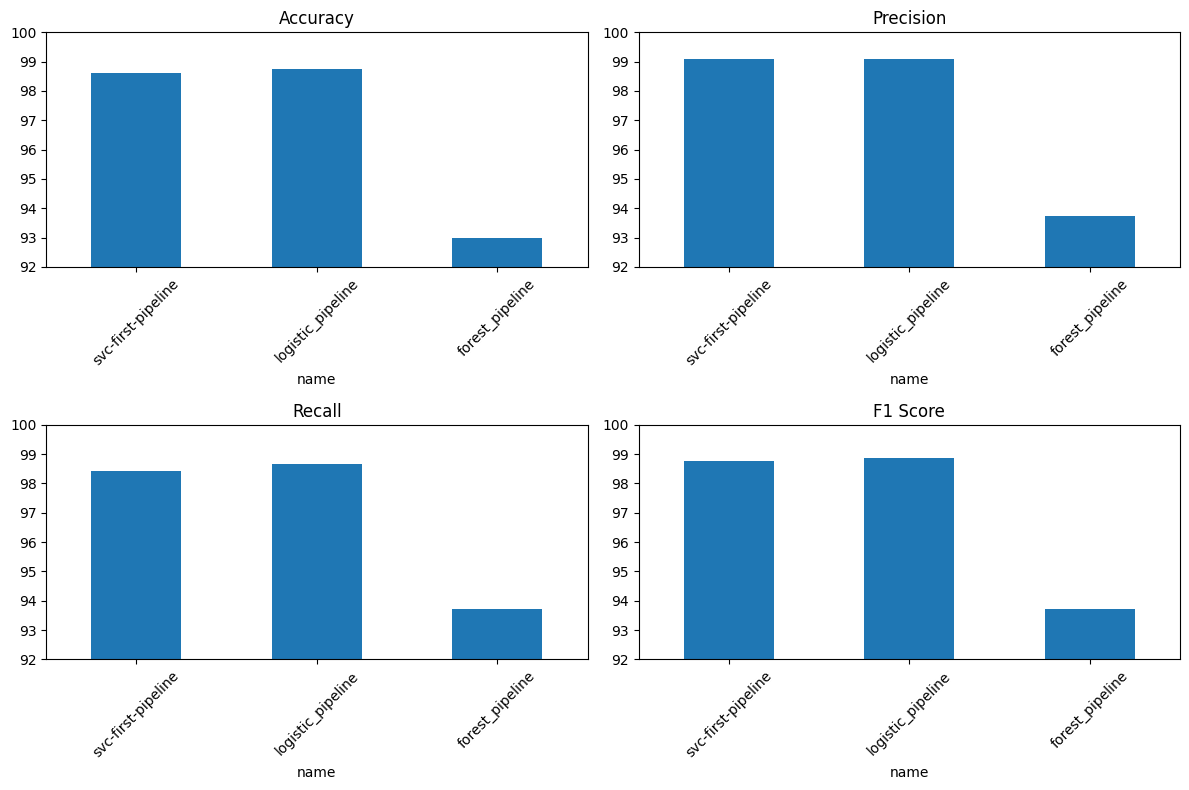

In [ ]:
results_df=pd.DataFrame([v_1_validation,logistic_validation,rand_forest_validation])
results_df=results_df.drop(columns=['confusion_matrix'])



fig, axes = plt.subplots(2, 2, figsize=(12,8))

metrics = ['accuracy', 'precision_score', 'recall_score', 'f1_score']
titles = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
results_df[metrics]=results_df[metrics]*100

for ax, metric, title in zip(axes.flat, metrics, titles):
    results_df.plot(
        kind='bar',
        x='name',
        y=metric,
        ax=ax,
        legend=False,
        title=title
    )
    ax.set_ylim(92, 100)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


#Fine Tuning and prediction
we fine tune logistic regression and get an l1 penalty model. The accuracy on the test set is 98.5% vs 99.2% on the validation set signaling a slight overfit over the validation set probably because of our fine tuning.

By inspecting the models we see that the most important feature is attendance_percentage which confirms our intuition in data exploration phase

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform,loguniform
logistic_reg_model=LogisticRegression(max_iter=300)
full_pipeline=Pipeline(
    [
        ('preprocessing',preprocessing_pipeline),
        ('logistic_model',logistic_reg_model)
    ]
)
param_distrib=[
    {'preprocessing__simpleimputer__strategy':['mean','median'],
     'logistic_model__penalty':['l1','l2'],
     'logistic_model__solver':['liblinear'],
     'logistic_model__intercept_scaling':[1,2,3,4],
     'logistic_model__C':loguniform(0.01,5)

    },

     {'preprocessing__simpleimputer__strategy':['mean','median'],
     'logistic_model__penalty':['elasticnet'],
     'logistic_model__solver':['saga'],
     'logistic_model__intercept_scaling':[1,2,3,4],
     'logistic_model__C':loguniform(0.01,5),
      'logistic_model__l1_ratio':uniform(0,1)

    }

]

rand_search=RandomizedSearchCV(
    full_pipeline,
    param_distributions=param_distrib,
    n_iter=100,
    scoring='accuracy',
    refit=True,
    cv=4,
    verbose=2,
    random_state=42,
    return_train_score=True
    ,error_score='raise'
    )

rand_search.fit(X_train.iloc[:,1:],y_train)

Fitting 4 folds for each of 100 candidates, totalling 400 fits
[CV] END logistic_model__C=1.4120355430626343, logistic_model__intercept_scaling=3, logistic_model__penalty=l1, logistic_model__solver=liblinear, preprocessing__simpleimputer__strategy=median; total time=   0.0s
[CV] END logistic_model__C=1.4120355430626343, logistic_model__intercept_scaling=3, logistic_model__penalty=l1, logistic_model__solver=liblinear, preprocessing__simpleimputer__strategy=median; total time=   0.0s
[CV] END logistic_model__C=1.4120355430626343, logistic_model__intercept_scaling=3, logistic_model__penalty=l1, logistic_model__solver=liblinear, preprocessing__simpleimputer__strategy=median; total time=   0.0s
[CV] END logistic_model__C=1.4120355430626343, logistic_model__intercept_scaling=3, logistic_model__penalty=l1, logistic_model__solver=liblinear, preprocessing__simpleimputer__strategy=median; total time=   0.0s
[CV] END logistic_model__C=0.40820721203399574, logistic_model__intercept_scaling=2, logi

RandomizedSearchCV(cv=4, error_score='raise',
                   estimator=Pipeline(steps=[('preprocessing',
                                              Pipeline(steps=[('simpleimputer',
                                                               SimpleImputer(strategy='median')),
                                                              ('standardscaler',
                                                               StandardScaler())])),
                                             ('logistic_model',
                                              LogisticRegression(max_iter=300))]),
                   n_iter=100,
                   param_distributions=[{'logistic_model__C': <scipy.stats._distn_infrastructure.rv_continuous_f...
                                         'logistic_model__intercept_scaling': [1,
                                                                               2,
                                                                               3,
                                                                               4],
                                         'logistic_model__l1_ratio': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x78463a87bb60>,
                                         'logistic_model__penalty': ['elasticnet'],
                                         'logistic_model__solver': ['saga'],
                                         'preprocessing__simpleimputer__strategy': ['mean',
                                                                                    'median']}],
                   random_state=42, return_train_score=True, scoring='accuracy',
                   verbose=2)

In [ ]:
rand_search.best_score_

np.float64(0.9924999999999999)

In [ ]:
rand_search.best_params_

{'logistic_model__C': np.float64(4.608697883952073),
 'logistic_model__intercept_scaling': 4,
 'logistic_model__penalty': 'l1',
 'logistic_model__solver': 'liblinear',
 'preprocessing__simpleimputer__strategy': 'median'}

In [ ]:
X_test,y_test=df_test.drop('result',axis=1),df_test['result'].copy()

## Predicring and Displaying  results

In [ ]:
pred=rand_search.best_estimator_.predict(X_test.iloc[:,1:])
classification_report(y_test,pred)

{'acc': 0.985,
 'prec': 0.9920634920634921,
 'recall_score': 0.984251968503937,
 'f1_score': 0.9881422924901185,
 'confusion_matrix': array([[ 72,   1],
        [  2, 125]])}

In [ ]:
data_plus_result=X_test.copy()
data_plus_result['result']=y_test.copy()
data_plus_result['pred_result']=pd.Series(pred,index=X_test.index.copy())
data_plus_result


,roll_no,study_hour_per_day,attendance_percentage,previous_marks,assignment_percentage,result,pred_result
521,522,1.0,55.03,66.51,85.73,1.0,1.0
737,738,3.0,45.66,50.26,87.87,1.0,1.0
740,741,8.0,75.49,48.47,70.68,1.0,1.0
660,661,1.0,32.16,55.02,94.25,1.0,1.0
411,412,2.0,55.10,42.95,69.25,0.0,0.0
...,...,...,...,...,...,...,...
408,409,10.0,39.55,68.14,67.34,0.0,0.0
332,333,3.0,53.95,59.89,65.73,0.0,0.0
208,209,2.0,54.90,73.10,54.72,0.0,0.0
613,614,4.0,52.13,61.42,84.61,1.0,1.0


## most important features
l1 penalty tends to perform feature selection. The most important feature is attendance_percentage which confirms our intuition in data exploration phase

In [ ]:
coefficients = pd.Series(
    rand_search.best_estimator_[1].coef_[0],
    index=X_train.columns[1:]
)
print(coefficients.sort_values(ascending=False))

attendance_percentage    13.535882
assignment_percentage    11.824123
previous_marks            5.715922
study_hour_per_day        1.347909
dtype: float64
